# ML deployment — section 05 (steps 33–36)

> **Development notebook.** Once final, converted to `util/ml_deployment.py` and called from `script/mlpipeline.ipynb`. Change this notebook first, then re-convert.

| Step | Section | Output |
|---|---|---|
| **33** | Register the signed-off models (MLflow) | `datamart/ml/mlflow/` (registry), `datamart/ml/deployment/v1/model_registry.yaml` |
| **34** | Deploy inference (monthly batch scoring from `@champion`) | `datamart/gold/model_predictions/loan_default_30dpd_6mob/`, `datamart/ml/deployment/v1/inference_log.csv` |
| **35** | Monitoring (simulated production on the OOT months) | `datamart/ml/deployment/v1/monitoring_report.csv`, `alert_log.csv` |
| **36** | Governance, refresh SOP, rollback drill, deployment options | `governance_policy.yaml`, `refresh_trigger_decisions.csv`, `rollback_drill.csv`, `governance_log.csv` |

**Inputs:** the signed-off models and model cards from step 30 (`datamart/ml/model_development/v1/final/`), and the step-31 evaluation.

In [1]:
import os, sys, json, hashlib, subprocess, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import joblib

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
import mlflow
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
sys.path.insert(0, PROJECT_DIR)
from util import dataprocessing_bronze as bronze
from util import dataprocessing_gold as gold
from util import ml_feature_engineering as fe

MD_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "model_development", "v1")      # section 04 outputs
FINAL_DIR = os.path.join(MD_DIR, "final")
DEP_VERSION = "v1"
DEP_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "deployment", DEP_VERSION)
MLFLOW_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "mlflow")
for d in (DEP_DIR, MLFLOW_DIR):
    os.makedirs(d, exist_ok=True)

REGISTERED_MODEL = "loan_default_30dpd_6mob"
EXPERIMENT = "cs611_a2_loan_default"
TRACKING_URI = "sqlite:///" + Path(MLFLOW_DIR, "mlflow.db").as_posix()             # local store, same on Windows / Linux
ARTIFACT_URI = Path(MLFLOW_DIR, "artifacts").as_uri()

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

spark = bronze.get_spark("ml_deployment")
print("MLflow", mlflow.__version__, "| tracking store:", TRACKING_URI)

C:\Users\alber\Documents\Github\CS_611\Assignment 2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow 3.17.1 | tracking store: sqlite:///C:/Users/alber/Documents/Github/CS_611/Assignment 2/datamart/ml/mlflow/mlflow.db


---

## Step 33 — Register the signed-off models (MLflow model registry)

**Inputs:** the step-30 sign-off with its approval and the step-31 evaluation.

| Item | Design |
|---|---|
| Store | local MLflow tracking + registry in **SQLite** (`datamart/ml/mlflow/mlflow.db`), artifacts under `datamart/ml/mlflow/artifacts/` — same on Windows and in Docker, no server needed |
| Registered model | **`loan_default_30dpd_6mob`** (one model name = one business problem) |
| Versions | baseline LR, champion XGB model A, challenger XGB model B — each from its own MLflow run |
| Aliases | **`@champion`** (what inference loads in step 34), **`@challenger`**, **`@baseline`** — moving an alias = promotion / rollback (step 36) without touching code |
| Each run logs | the full pipeline (preprocessing + model) with **input/output signature** and input example; parameters; threshold; CV, validation, test and OOT metrics; lineage tags (label, split, feature store, data contract, git commit, model checksum); model card, sign-off, approval, evaluation files and key charts |
| Format | **skops** (MLflow's default for scikit-learn; unlike pickle it only loads explicitly trusted types — here scikit-learn plus an audited list of `numpy` / `xgboost` types) |
| Idempotent | a version is matched by the model's SHA-256 — re-running the pipeline does not create duplicate versions |
| Check | the model loaded back from the registry (`models:/…@champion`) reproduces the step-31 predictions exactly |

In [2]:
# 1. Inputs: sign-off approval, final evaluation and baseline summary from section 04
with open(os.path.join(FINAL_DIR, "signoff_approval.yaml"), encoding="utf-8") as f:
    APPROVAL = yaml.safe_load(f)
with open(os.path.join(MD_DIR, "final_evaluation.yaml"), encoding="utf-8") as f:
    EVAL = yaml.safe_load(f)
final_eval = pd.read_csv(os.path.join(MD_DIR, "final_evaluation.csv"))
with open(os.path.join(MD_DIR, "baseline_summary.json"), encoding="utf-8") as f:
    BASELINE_SUMMARY = json.load(f)
print(f"Sign-off approved by {APPROVAL['approved_by']}; step-31 evaluation from {EVAL['evaluated_ts']}")

# 2. What gets registered
cards = {}
for fn in sorted(os.listdir(FINAL_DIR)):
    if fn.startswith("model_card_"):
        with open(os.path.join(FINAL_DIR, fn), encoding="utf-8") as f:
            c = yaml.safe_load(f)
        cards[c["role"]] = c
FEATURE_SETS = fe.load_feature_sets()
A_RAW_LINEAR = FEATURE_SETS["A_raw"]["linear"]
EVAL_NAME = {"champion": "champion XGB model A", "challenger": "challenger XGB model B", "baseline": "baseline LR__A_raw"}
TO_REGISTER = {
    "champion": dict(path=os.path.join(FINAL_DIR, cards["champion"]["artifact"].split("/")[-1]), card=cards["champion"],
                     features=cards["champion"]["features"], threshold=cards["champion"]["operating_threshold"]),
    "challenger": dict(path=os.path.join(FINAL_DIR, cards["challenger"]["artifact"].split("/")[-1]), card=cards["challenger"],
                       features=cards["challenger"]["features"], threshold=cards["challenger"]["operating_threshold"]),
    "baseline": dict(path=os.path.join(MD_DIR, "artifacts", "baseline_logreg_A_raw.joblib"), card=None, features=A_RAW_LINEAR,
                     threshold=float(final_eval.query("model == 'baseline LR__A_raw'")["threshold"].iloc[0])),
}
pd.DataFrame([{"alias": k, "file": os.path.relpath(v["path"], MD_DIR), "features": len(v["features"]),
               "threshold": v["threshold"], "sha256": sha256(v["path"])[:12] + "…"} for k, v in TO_REGISTER.items()])

Sign-off approved by albertsoh; step-31 evaluation from 2026-10-21T04:02:33Z


,alias,file,features,threshold,sha256
0,champion,final\champion_XGB_modelA.joblib,30,0.2867,9fc7bd826813…
1,challenger,final\challenger_XGB_modelB.joblib,25,0.3085,28578182a720…
2,baseline,artifacts\baseline_logreg_A_raw.joblib,43,0.3239,3d00e79c05d0…


In [3]:
# 3. Example input rows (features only, no labels) for the signature, input example and the reload check
ctx = gold.load_eda_data(spark)
afe = pd.read_parquet(os.path.join(fe.FE_DIR, "autofe_features.parquet")).drop(columns="partition")
features_all = ctx["data"].merge(afe, on="loan_id", how="left")
holdout_pred = pd.read_parquet(os.path.join(MD_DIR, "final_predictions_holdout.parquet"))
check_ids = holdout_pred[holdout_pred["partition"] == "oot"]["loan_id"].head(500)
check_X = features_all.set_index("loan_id").loc[check_ids].reset_index()
print(f"Reload check on {len(check_X)} OOT loans; feature table has {features_all.shape[1] - 2} columns")

Reload check on 500 OOT loans; feature table has 89 columns


In [4]:
# 4. Register (idempotent: an existing version with the same model checksum is reused)
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)
client = MlflowClient()
if client.get_experiment_by_name(EXPERIMENT) is None:
    client.create_experiment(EXPERIMENT, artifact_location=ARTIFACT_URI)
mlflow.set_experiment(EXPERIMENT)

def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=PROJECT_DIR,
                                       stderr=subprocess.DEVNULL).decode().strip()
    except Exception:
        return "n/a"

with open(os.path.join(PROJECT_DIR, "config", "data_contract.yaml"), encoding="utf-8") as f:
    CONTRACT_VERSION = str(yaml.safe_load(f).get("version", "n/a"))

def metrics_for(alias):
    m = {}
    for _, r in final_eval[final_eval["model"] == EVAL_NAME[alias]].iterrows():
        for k in ["pr_auc", "roc_auc", "brier", "precision", "recall", "f1", "flagged_share"]:
            m[f"{r['partition']}_{k}"] = float(r[k])
    m["cv_pr_auc"] = float(TO_REGISTER[alias]["card"]["cv_pr_auc"]) if TO_REGISTER[alias]["card"] \
        else float(BASELINE_SUMMARY["baseline_cv_pr_auc_mean"])
    return m

ARTIFACTS = {"governance": [os.path.join(FINAL_DIR, f) for f in ["model_selection_signoff.yaml", "signoff_approval.yaml"]]
                           + [os.path.join(MD_DIR, f) for f in ["metric_contract.yaml", "final_evaluation.yaml",
                                                                "error_robustness_summary.yaml", "reduced_features.json",
                                                                "best_params.yaml"]],
             "charts": [os.path.join(MD_DIR, "charts", f) for f in ["30_1_threshold_selection.png", "30_4_final_shap_importance.png",
                                                                     "31_1_final_pr_auc.png", "31_3_oot_by_month.png",
                                                                     "32_3_input_robustness.png"]]}

import skops.io
TRUSTED_PACKAGES = {"numpy", "xgboost"}            # beyond scikit-learn, only these packages' types may be trusted
existing = {v.tags.get("model_sha256"): v for v in client.search_model_versions(f"name='{REGISTERED_MODEL}'")}
reg_rows = []
for alias, spec in TO_REGISTER.items():
    model_sha = sha256(spec["path"])
    pipe = joblib.load(spec["path"])
    if model_sha in existing:
        mv = existing[model_sha]
        action = "reused (same checksum)"
    else:
        X_ex = check_X[spec["features"]].head(5)
        signature = infer_signature(X_ex, pipe.predict_proba(X_ex))
        with mlflow.start_run(run_name=f"{alias}") as run:
            mlflow.set_tags({"role": alias, "label": gold.LABEL_DEF, "split_version": "v1", "feature_store": "gold v1",
                             "feature_engineering": "v1", "data_contract_version": CONTRACT_VERSION,
                             "git_commit": git_commit(), "model_sha256": model_sha, "checklist_step": "33",
                             "oot_evaluable": str(alias != "challenger")})
            params = {"n_features": len(spec["features"]), "operating_threshold": spec["threshold"],
                      "threshold_rule": "max F1 on validation", "class_weighting": "none",
                      "algorithm": type(pipe.named_steps["model"]).__name__}
            if spec["card"]:
                params.update({f"xgb_{k}": v for k, v in spec["card"]["params"].items()})
            mlflow.log_params(params)
            mlflow.log_metrics(metrics_for(alias))
            mlflow.log_dict({"features": spec["features"]}, "features.json")
            if spec["card"]:
                mlflow.log_dict(spec["card"], "model_card.yaml")
            for group, files in ARTIFACTS.items():
                for p in files:
                    mlflow.log_artifact(p, artifact_path=group)
            # skops format (MLflow default, safer than pickle): only explicitly trusted non-sklearn types may load
            trusted = skops.io.get_untrusted_types(data=skops.io.dumps(pipe))
            assert all(t.split(".")[0] in TRUSTED_PACKAGES for t in trusted), f"unexpected types: {trusted}"
            mlflow.set_tag("skops_trusted_types", ", ".join(trusted) or "none")
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                info = mlflow.sklearn.log_model(pipe, name="model", signature=signature, input_example=X_ex,
                                                pyfunc_predict_fn="predict_proba", registered_model_name=REGISTERED_MODEL,
                                                serialization_format="skops", skops_trusted_types=trusted)
        mv = client.get_model_version(REGISTERED_MODEL, info.registered_model_version)
        for k, v in {"role": alias, "model_sha256": model_sha, "operating_threshold": str(spec["threshold"]),
                     "oot_evaluable": str(alias != "challenger"), "approved_by": APPROVAL["approved_by"]}.items():
            client.set_model_version_tag(REGISTERED_MODEL, mv.version, k, v)
        action = "registered"
    client.set_registered_model_alias(REGISTERED_MODEL, alias, mv.version)
    reg_rows.append(dict(alias=alias, version=int(mv.version), action=action, run_id=mv.run_id,
                         model_uri=f"models:/{REGISTERED_MODEL}@{alias}", threshold=spec["threshold"],
                         features=len(spec["features"]), model_sha256=model_sha))
client.update_registered_model(REGISTERED_MODEL, description=(
    "Probability that a new loan reaches 30+ days past due at month-on-book 6 (label 30dpd_6mob), scored at loan start. "
    "@champion = XGBoost without clickstream (deployable, OOT-validated); @challenger = XGBoost with clickstream "
    "(needs the clickstream feed); @baseline = logistic regression reference."))
registry = pd.DataFrame(reg_rows)
registry.drop(columns="model_sha256")

,alias,version,action,run_id,model_uri,threshold,features
0,champion,1,reused (same checksum),2a70b3bd934e4104af6068afec1c5066,models:/loan_default_30dpd_6mob@champion,0.2867,30
1,challenger,2,reused (same checksum),799cc397c27742c0b924745795003247,models:/loan_default_30dpd_6mob@challenger,0.3085,25
2,baseline,3,reused (same checksum),587060a814c74dd28fe29396966d56d8,models:/loan_default_30dpd_6mob@baseline,0.3239,43


In [5]:
# 5. Check: models loaded back from the registry reproduce the step-31 predictions; aliases point to the right versions
checks = []
hp = holdout_pred.set_index("loan_id").loc[check_ids]
for alias, col in [("champion", "p_champion"), ("challenger", "p_challenger"), ("baseline", "p_baseline")]:
    uri = f"models:/{REGISTERED_MODEL}@{alias}"
    feats = TO_REGISTER[alias]["features"]
    sk = mlflow.sklearn.load_model(uri)
    p_sk = sk.predict_proba(check_X[feats])[:, 1]
    py = mlflow.pyfunc.load_model(uri)
    out = py.predict(check_X[feats])
    p_py = np.asarray(out)[:, 1] if np.asarray(out).ndim == 2 else np.asarray(out)
    expected = hp[col].values
    ok_ref = np.isnan(expected).all() or np.allclose(p_sk, expected, atol=1e-6)     # challenger has no OOT reference
    if np.isnan(expected).all():                                                   # compare with the signed-off file instead
        ok_ref = np.allclose(p_sk, joblib.load(TO_REGISTER[alias]["path"]).predict_proba(check_X[feats])[:, 1], atol=1e-9)
    mv = client.get_model_version_by_alias(REGISTERED_MODEL, alias)
    checks.append(dict(alias=alias, version=int(mv.version), sklearn_matches_signed_off=bool(ok_ref),
                       pyfunc_matches_sklearn=bool(np.allclose(p_py, p_sk, atol=1e-9)),
                       version_sha_matches=mv.tags.get("model_sha256") == sha256(TO_REGISTER[alias]["path"]),
                       signature_inputs=len(py.metadata.get_input_schema().inputs)))
reg_checks = pd.DataFrame(checks)
assert reg_checks[["sklearn_matches_signed_off", "pyfunc_matches_sklearn", "version_sha_matches"]].all().all()
n_versions = len(client.search_model_versions(f"name='{REGISTERED_MODEL}'"))
print(f"Registry check passed; '{REGISTERED_MODEL}' has {n_versions} version(s)")
reg_checks

Registry check passed; 'loan_default_30dpd_6mob' has 3 version(s)


,alias,version,sklearn_matches_signed_off,pyfunc_matches_sklearn,version_sha_matches,signature_inputs
0,champion,1,True,True,True,30
1,challenger,2,True,True,True,25
2,baseline,3,True,True,True,43


In [6]:
# 6. Registry record for steps 34-36 (inference loads the alias, not a file path)
record = {
    "step": 33, "version": DEP_VERSION, "registered_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "tracking_uri": "sqlite:///datamart/ml/mlflow/mlflow.db (relative to the project folder)",
    "experiment": EXPERIMENT, "registered_model": REGISTERED_MODEL,
    "aliases": {r["alias"]: {"version": int(r["version"]), "model_uri": r["model_uri"], "run_id": r["run_id"],
                             "operating_threshold": float(r["threshold"]), "n_features": int(r["features"]),
                             "model_sha256": r["model_sha256"]} for r in reg_rows},
    "inference_uses": f"models:/{REGISTERED_MODEL}@champion",
    "approval": {k: APPROVAL[k] for k in ["approved_by", "approved_ts"]},
    "ui": "mlflow ui --backend-store-uri sqlite:///datamart/ml/mlflow/mlflow.db  (run from the project folder; "
          "in Docker add --host 0.0.0.0 and publish port 5000)",
}
with open(os.path.join(DEP_DIR, "model_registry.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(record, f, sort_keys=False)
registry.drop(columns=["model_sha256"]).to_csv(os.path.join(DEP_DIR, "model_registry.csv"), index=False)
print(yaml.safe_dump(record["aliases"], sort_keys=False))

champion:
  version: 1
  model_uri: models:/loan_default_30dpd_6mob@champion
  run_id: 2a70b3bd934e4104af6068afec1c5066
  operating_threshold: 0.2867
  n_features: 30
  model_sha256: 9fc7bd826813ce3885d1a4cc1e8ab845483753e18117e1b1dc0d64d5bbd0abe5
challenger:
  version: 2
  model_uri: models:/loan_default_30dpd_6mob@challenger
  run_id: 799cc397c27742c0b924745795003247
  operating_threshold: 0.3085
  n_features: 25
  model_sha256: 28578182a7207947c3cda92155002d9db9238160b8ec293eb0cd9a063f62098c
baseline:
  version: 3
  model_uri: models:/loan_default_30dpd_6mob@baseline
  run_id: 587060a814c74dd28fe29396966d56d8
  operating_threshold: 0.3239
  n_features: 43
  model_sha256: 3d00e79c05d090ca7f5558ccca8c90f4634fc56f976ce533385a0e437b20d935



### Step 33 summary

- Registered model **`loan_default_30dpd_6mob`** with three versions and aliases **`@champion`** (XGB model A), **`@challenger`** (XGB model B) and **`@baseline`** (LR) — registered from the approved step-30 sign-off and the step-31 evaluation.
- Each version carries the full pipeline with signature, parameters, threshold, CV / validation / test / OOT metrics, lineage tags and the governance files.
- Loading `models:/loan_default_30dpd_6mob@champion` reproduces the step-31 predictions exactly; re-running does not create duplicates.
- **Next — step 34:** batch inference loads `@champion` from the registry (not a file path), applies the stored threshold and writes predictions.
- To browse: `mlflow ui --backend-store-uri sqlite:///datamart/ml/mlflow/mlflow.db` from the project folder, then open http://127.0.0.1:5000.

---

## Step 34 — Deploy inference (batch scoring from the registry)

**How the model is used:** a loan is scored once, at `loan_start_date`, with the latest features available on or before that date. Scoring runs as a **monthly batch** over the loans that start in that month.

| Item | Design |
|---|---|
| Model | loaded by **alias** `models:/loan_default_30dpd_6mob@champion` — promotion / rollback = move the alias, no code change; threshold and checksum read from the version's registry tags |
| Inputs | Gold feature store v1 rows for the month (as-of joined in step 10) + the 20 OpenFE formulas **recomputed row by row** with `fe.apply_catalog` (nothing fitted at inference; the training feature file is not reused) |
| Output | `datamart/gold/model_predictions/loan_default_30dpd_6mob/` — one Parquet file per month (lab layout), written atomically; columns: loan, start date, probability, decision flag, threshold, top-3 reason codes (SHAP), model version, checksum, scoring time |
| Labels | **not read** — inference never needs outcomes |
| Simulation | the months after training: loans starting **2024-07 → 2025-01** (the OOT period) — the period the model would have been used in |
| Checks | one row per loan; probabilities valid; every feature snapshot on or before the loan start; **predictions equal the step-31 champion predictions** (deployed path = evaluated model); schema enforced by the model signature |

In [7]:
from pyspark.sql import functions as F

PRED_DIR = os.path.join(PROJECT_DIR, "datamart", "gold", "model_predictions", REGISTERED_MODEL)
CHART_DIR = os.path.join(DEP_DIR, "charts")
for d in (PRED_DIR, CHART_DIR):
    os.makedirs(d, exist_ok=True)
with open(os.path.join(gold.SPLIT_DIR, "split_config.yaml"), encoding="utf-8") as f:
    INFERENCE_START = yaml.safe_load(f)["oot_start"]                 # first month after the development period
SCORING_COL = gold.SCORING_COL
CATALOG = fe.load_catalog()

def resolve_alias(alias="champion"):
    # The registry decides which model runs: version, threshold and checksum come from the alias' version tags
    mv = client.get_model_version_by_alias(REGISTERED_MODEL, alias)
    uri = f"models:/{REGISTERED_MODEL}@{alias}"
    pyfunc_model = mlflow.pyfunc.load_model(uri)
    sk_model = mlflow.sklearn.load_model(uri)
    return dict(alias=alias, version=int(mv.version), uri=uri, threshold=float(mv.tags["operating_threshold"]),
                model_sha256=mv.tags["model_sha256"], pyfunc=pyfunc_model, sklearn=sk_model,
                features=pyfunc_model.metadata.get_input_schema().input_names())

def load_scoring_rows(month_start):
    # Gold features of loans starting in the month (no labels, no split manifest) + generated features
    start = pd.Timestamp(month_start)
    end = start + pd.offsets.MonthBegin(1)
    fs = gold.get_features(spark)
    feats = gold.feature_list(fs)
    asof_cols = [c for c in fs.columns if c.startswith("_asof_")]
    rows = (fs.filter((F.col(SCORING_COL) >= F.lit(start.date())) & (F.col(SCORING_COL) < F.lit(end.date())))
              .select("loan_id", "Customer_ID", SCORING_COL, *asof_cols, *feats).toPandas())
    binary = [c for c in feats if c.endswith("_invalid") or c in gold.LOAN_TYPE_COLUMNS or c == "type_of_loan_unknown"]
    for c in binary:                                   # same typing rule as training (gold.load_eda_data)
        rows[c] = rows[c].astype(float)
    return fe.apply_catalog(rows, CATALOG), asof_cols

def reason_codes(sk_model, X, top=3):
    # Top features pushing each loan's risk UP (SHAP log-odds contributions, summed back to original features)
    import xgboost as xgb
    pre, model = sk_model.named_steps["pre"], sk_model.named_steps["model"]
    contrib = model.get_booster().predict(xgb.DMatrix(pre.transform(X)), pred_contribs=True)[:, :-1]
    cats = sorted([c for c in X.columns if X[c].dtype == object], key=len, reverse=True)
    owner = []
    for name in pre.get_feature_names_out():
        part, col = name.split("__", 1)
        if part == "missing_ind":
            col = col[len("missingindicator_"):]
        elif part == "cat":
            col = next(c for c in cats if col.startswith(c + "_"))
        owner.append(col)
    owner = np.array(owner)
    per_feat = pd.DataFrame({f: contrib[:, owner == f].sum(axis=1) for f in X.columns})
    out = []
    for _, r in per_feat.iterrows():
        up = r[r > 0].sort_values(ascending=False).head(top)
        out.append([f"{f} (+{v:.2f})" for f, v in up.items()] + [""] * (top - len(up)))
    return pd.DataFrame(out, columns=[f"reason_{i + 1}" for i in range(top)])

def score_month(month_start, alias="champion"):
    m = resolve_alias(alias)
    rows, asof_cols = load_scoring_rows(month_start)
    if rows.empty:
        return None, None
    X = rows[m["features"]]
    p = np.asarray(m["pyfunc"].predict(X))[:, 1]             # signature-enforced scoring path
    for c in asof_cols:                                       # as-of rule: no snapshot after the loan start
        snap = pd.to_datetime(rows[c], errors="coerce")       # missing snapshot (source absent) -> NaT
        ok = snap.isna() | (snap <= pd.to_datetime(rows[SCORING_COL]))
        assert ok.all(), f"{c}: feature snapshot after loan start"
    out = pd.DataFrame({"loan_id": rows["loan_id"], "Customer_ID": rows["Customer_ID"],
                        "loan_start_date": pd.to_datetime(rows[SCORING_COL]).dt.strftime("%Y-%m-%d"),
                        "default_probability": p, "threshold": m["threshold"],
                        "flag_high_risk": (p >= m["threshold"]).astype(int)})
    out = pd.concat([out, reason_codes(m["sklearn"], X)], axis=1)
    out = out.assign(model_name=REGISTERED_MODEL, model_alias=alias, model_version=m["version"],
                     model_sha256=m["model_sha256"], feature_store="gold v1",
                     scored_ts=datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"))
    assert out["loan_id"].is_unique and out["default_probability"].between(0, 1).all()
    month_tag = pd.Timestamp(month_start).strftime("%Y_%m_%d")
    path = os.path.join(PRED_DIR, f"{REGISTERED_MODEL}_{alias}_predictions_{month_tag}.parquet")
    tmp = path + ".tmp"
    out.to_parquet(tmp, index=False)
    os.replace(tmp, path)                                     # atomic: a re-run replaces the month cleanly
    log = dict(month=pd.Timestamp(month_start).strftime("%Y-%m"), loans=len(out), model_alias=alias,
               model_version=m["version"], threshold=m["threshold"], mean_probability=float(p.mean()),
               flagged_share=float(out["flag_high_risk"].mean()), file=os.path.relpath(path, PROJECT_DIR).replace("\\", "/"),
               file_sha256=sha256(path), scored_ts=out["scored_ts"].iloc[0])
    return out, log

In [8]:
# Run the monthly batches for the period after training
months = pd.date_range(INFERENCE_START, "2025-01-01", freq="MS")
logs, scored = [], []
for mth in months:
    out, log = score_month(mth)
    if out is not None:
        scored.append(out); logs.append(log)
        print(f"{log['month']}: {log['loans']:,} loans scored with @{log['model_alias']} v{log['model_version']} | "
              f"mean p {log['mean_probability']:.3f} | flagged {log['flagged_share']:.1%}")
scored = pd.concat(scored, ignore_index=True)
inference_log = pd.DataFrame(logs)
inference_log.to_csv(os.path.join(DEP_DIR, "inference_log.csv"), index=False)

2024-07: 505 loans scored with @champion v1 | mean p 0.289 | flagged 37.8%


2024-08: 543 loans scored with @champion v1 | mean p 0.283 | flagged 36.3%


2024-09: 493 loans scored with @champion v1 | mean p 0.286 | flagged 36.3%


2024-10: 456 loans scored with @champion v1 | mean p 0.265 | flagged 31.8%


2024-11: 488 loans scored with @champion v1 | mean p 0.286 | flagged 35.9%


2024-12: 515 loans scored with @champion v1 | mean p 0.254 | flagged 30.1%


2025-01: 526 loans scored with @champion v1 | mean p 0.286 | flagged 35.6%


In [9]:
# Checks: the deployed path reproduces the evaluated champion; one row per loan; nothing missing
ref = pd.read_parquet(os.path.join(MD_DIR, "final_predictions_holdout.parquet"))
ref = ref[ref["partition"] == "oot"][["loan_id", "p_champion"]]
cmp = scored.merge(ref, on="loan_id", how="outer", indicator=True)
inf_checks = pd.DataFrame([
    dict(check="every OOT loan scored exactly once", passed=bool((cmp["_merge"] == "both").all() and scored["loan_id"].is_unique),
         observed=f"{len(scored):,} scored vs {len(ref):,} OOT loans"),
    dict(check="predictions equal the step-31 champion predictions", passed=bool(np.allclose(
        cmp["default_probability"], cmp["p_champion"], atol=1e-6)),
         observed=f"max abs diff {np.abs(cmp['default_probability'] - cmp['p_champion']).max():.2e}"),
    dict(check="probabilities valid, no missing values", passed=bool(scored["default_probability"].between(0, 1).all()
                                                                      and scored["default_probability"].notna().all()),
         observed=f"range {scored['default_probability'].min():.3f}–{scored['default_probability'].max():.3f}"),
    dict(check="threshold and version from the registry alias", passed=bool(
        (scored["threshold"] == TO_REGISTER["champion"]["threshold"]).all()
        and (scored["model_version"] == client.get_model_version_by_alias(REGISTERED_MODEL, "champion").version).all()),
         observed=f"threshold {scored['threshold'].iloc[0]}, version {scored['model_version'].iloc[0]}"),
    dict(check="flag rate matches step 31 at the same threshold", passed=bool(abs(scored["flag_high_risk"].mean()
        - final_eval.query("partition == 'oot' and model == 'champion XGB model A'")["flagged_share"].iloc[0]) < 1e-9),
         observed=f"{scored['flag_high_risk'].mean():.2%} flagged"),
])
inf_checks.to_csv(os.path.join(DEP_DIR, "inference_checks.csv"), index=False)
assert inf_checks["passed"].all(), inf_checks
display(inf_checks.style.hide(axis="index"))
scored[["loan_id", "loan_start_date", "default_probability", "flag_high_risk", "reason_1", "reason_2", "reason_3",
        "model_version"]].head(5).style.hide(axis="index").format({"default_probability": "{:.3f}"})

check,passed,observed
every OOT loan scored exactly once,True,"3,526 scored vs 3,526 OOT loans"
predictions equal the step-31 champion predictions,True,max abs diff 0.00e+00
"probabilities valid, no missing values",True,range 0.001–0.964
threshold and version from the registry alias,True,"threshold 0.2867, version 1"
flag rate matches step 31 at the same threshold,True,34.86% flagged


loan_id,loan_start_date,default_probability,flag_high_risk,reason_1,reason_2,reason_3,model_version
CUS_0x1eae_2024_07_01,2024-07-01,0.107,0,Monthly_Balance (+0.17),afe_div__Total_EMI_per_month__Monthly_Balance (+0.11),afe_mul__Age__Num_Credit_Inquiries (+0.09),1
CUS_0x5480_2024_07_01,2024-07-01,0.010,0,Num_Credit_Card (+0.09),Credit_Utilization_Ratio (+0.05),afe_mul__Age__Num_Credit_Inquiries (+0.05),1
CUS_0x56d6_2024_07_01,2024-07-01,0.320,1,Payment_Behaviour (+0.41),afe_mul__Num_Credit_Inquiries__Outstanding_Debt (+0.18),Monthly_Balance (+0.18),1
CUS_0x806c_2024_07_01,2024-07-01,0.863,1,afe_mul__Interest_Rate__Outstanding_Debt (+0.67),Payment_Behaviour (+0.26),afe_mul__Changed_Credit_Limit__Outstanding_Debt (+0.24),1
CUS_0x30de_2024_07_01,2024-07-01,0.443,1,afe_mul__Interest_Rate__Outstanding_Debt (+0.28),Payment_Behaviour (+0.24),afe_mul__Delay_from_due_date__Outstanding_Debt (+0.16),1


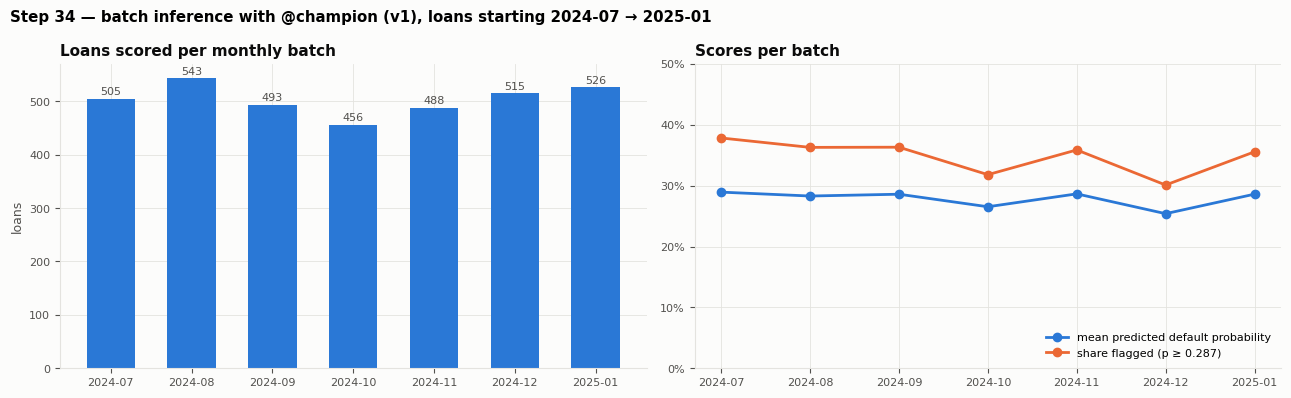

In [10]:
# Chart: monthly batches — volume, mean predicted probability and share flagged
import matplotlib.pyplot as plt
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 8, "font.size": 9, "lines.linewidth": 2})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(inference_log))
axes[0].bar(x, inference_log["loans"], color=SERIES[0], width=0.6)
for xi, v in zip(x, inference_log["loans"]):
    axes[0].text(xi, v + 8, f"{v:,}", ha="center", fontsize=8, color=INK_2)
axes[0].set_title("Loans scored per monthly batch")
axes[0].set_ylabel("loans")
axes[1].plot(x, inference_log["mean_probability"], "o-", color=SERIES[0], label="mean predicted default probability")
axes[1].plot(x, inference_log["flagged_share"], "o-", color=SERIES[1], label=f"share flagged (p ≥ {inference_log['threshold'].iloc[0]:.3f})")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_ylim(0, 0.5)
axes[1].set_title("Scores per batch")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xticks(x, inference_log["month"])
fig.suptitle(f"Step 34 — batch inference with @champion (v{inference_log['model_version'].iloc[0]}), loans starting "
             f"{inference_log['month'].iloc[0]} → {inference_log['month'].iloc[-1]}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "34_1_batch_inference.png"), dpi=130, bbox_inches="tight")
plt.show()

In [11]:
# Most frequent reasons behind high-risk flags (first reason code of flagged loans)
top_reasons = (scored.loc[scored["flag_high_risk"] == 1, "reason_1"].str.replace(r" \(\+.*\)$", "", regex=True)
               .value_counts(normalize=True).head(8).rename("share of flagged loans").to_frame())
top_reasons.to_csv(os.path.join(DEP_DIR, "inference_top_reasons.csv"))
print(f"Prediction files in {os.path.relpath(PRED_DIR, PROJECT_DIR)}:", len([f for f in os.listdir(PRED_DIR) if f.endswith('.parquet')]))
top_reasons.style.format("{:.0%}")

Prediction files in datamart\gold\model_predictions\loan_default_30dpd_6mob: 7


,share of flagged loans
reason_1,
afe_mul__Interest_Rate__Outstanding_Debt,77%
afe_sub__Delay_from_due_date__Num_of_Delayed_Payment,6%
afe_div__Num_Credit_Card__Num_of_Delayed_Payment,4%
Payment_Behaviour,3%
Outstanding_Debt,2%
afe_sub__Num_Bank_Accounts__Delay_from_due_date,2%
afe_mul__Num_Credit_Inquiries__Outstanding_Debt,1%
afe_add__Interest_Rate__num_loan_types,1%


### Step 34 summary

- **Batch inference** scores each month's new loans at loan start with the model behind **`@champion`** (version, threshold and checksum from the registry), using the Gold feature store and the OpenFE formulas recomputed row by row — no fitting and no labels at inference.
- **Output:** one Parquet file per month in `datamart/gold/model_predictions/loan_default_30dpd_6mob/` with probability, high-risk flag, three reason codes and model lineage; `inference_log.csv` records every batch with a file checksum.
- **Checks passed:** every loan scored once; predictions **identical** to the step-31 evaluation (deployed path = evaluated model); as-of rule holds; threshold and version come from the alias.
- **Next — step 35:** monitoring replayed on these batches.

---

## Step 35 — Monitoring (simulated production on the out-of-time months)

There is no live data yet, so production is **replayed** on the months after training: loans starting **2024-07 → 2025-01**, already scored month by month in step 34. Their outcomes exist in the label store, so the delayed label-based checks can be simulated too.

| Layer | When available | Checks | Rule (`monitoring_config.yaml`) |
|---|---|---|---|
| **Data quality** | at scoring | volume; missing-value rate per input vs training | missing rate up > 10 pp → ALERT |
| **Input drift** | at scoring | **PSI** of every model input vs the training reference | PSI 0.10–0.25 WATCH · > 0.25 ALERT |
| **Score drift** | at scoring | PSI of predicted probabilities; share flagged | score PSI rules as above; flagged share > 10 pp from validation → ALERT |
| **Performance** | **6 months later** (`expected_outcome_date`) | PR-AUC, recall, precision at the registered threshold; calibration (mean predicted − actual) | PR-AUC > 0.05 below validation → ALERT; calibration gap > 5 pp → ALERT; recall > 10 pp below validation → WATCH |

- **Reference** = training loans (features and champion scores), frozen in `monitoring_reference.json` — monitoring never refits anything.
- **Challenger B is monitored on its inputs too**, to show what monitoring would have caught: its clickstream features stop after 2024-06.
- Diagnostic only: no model change here; step 36 turns the results into refresh decisions.

In [12]:
# Configuration (thresholds) and the frozen training reference
from sklearn.metrics import average_precision_score
MON_CFG = {"psi_bins": 10, "psi_watch": 0.10, "psi_alert": 0.25, "missing_increase_alert_pp": 10.0,
           "flagged_share_alert_pp": 10.0, "pr_auc_drop_alert": 0.05, "calibration_gap_alert_pp": 5.0,
           "recall_drop_watch_pp": 10.0, "label_delay": "6 months (label = 30+ DPD at month-on-book 6)",
           "reference": "training partition (step 14 split), features + champion scores"}
with open(os.path.join(DEP_DIR, "monitoring_config.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(MON_CFG, f, sort_keys=False)

champ = resolve_alias("champion")
chall = resolve_alias("challenger")
train_rows = fe.apply_catalog(ctx["data"][ctx["data"]["partition"] == "train"].copy(), CATALOG)
MON_FEATURES = {"champion": champ["features"], "challenger": chall["features"]}
CAT_COLS = set(ctx["categorical"])

def make_bins(values):
    # decile edges from the reference (numeric) or category list (categorical); missing is its own bin
    v = values.dropna()
    if values.name in CAT_COLS:
        return {"type": "categorical", "levels": sorted(v.astype(str).unique().tolist())}
    edges = np.unique(np.quantile(v.astype(float), np.linspace(0, 1, MON_CFG["psi_bins"] + 1)))
    return {"type": "numeric", "edges": edges[1:-1].tolist()}

def shares(values, spec):
    n = len(values)
    miss = values.isna()
    if spec["type"] == "categorical":
        s = values[~miss].astype(str)
        counts = [int((s == lv).sum()) for lv in spec["levels"]] + [int((~s.isin(spec["levels"])).sum())]   # + unseen
    else:
        idx = np.searchsorted(spec["edges"], values[~miss].astype(float), side="right")
        counts = np.bincount(idx, minlength=len(spec["edges"]) + 1).tolist()
    return np.array(counts + [int(miss.sum())], dtype=float) / max(n, 1)

def psi(ref_share, cur_share, eps=1e-4):
    r, c = np.clip(ref_share, eps, None), np.clip(cur_share, eps, None)
    return float(np.sum((c - r) * np.log(c / r)))

REF = {}
for role, feats in MON_FEATURES.items():
    for f_ in feats:
        if f_ not in REF:
            spec = make_bins(train_rows[f_].rename(f_))
            REF[f_] = {**spec, "ref_share": shares(train_rows[f_], spec).tolist(),
                       "ref_missing_pct": float(train_rows[f_].isna().mean() * 100)}
train_scores = champ["sklearn"].predict_proba(train_rows[champ["features"]])[:, 1]
SCORE_SPEC = {"type": "numeric", "edges": np.unique(np.quantile(train_scores, np.linspace(0, 1, 11)))[1:-1].tolist()}
SCORE_REF = shares(pd.Series(train_scores), SCORE_SPEC)
VAL_REF = final_eval.query("partition == 'validation' and model == 'champion XGB model A'").iloc[0]
with open(os.path.join(DEP_DIR, "monitoring_reference.json"), "w", encoding="utf-8") as f:
    json.dump({"features": REF, "score": {**SCORE_SPEC, "ref_share": SCORE_REF.tolist()},
               "validation": {k: float(VAL_REF[k]) for k in ["pr_auc", "recall", "precision", "flagged_share"]},
               "reference_rows": int(len(train_rows))}, f, indent=1)
print(f"Reference: {len(train_rows):,} training loans, {len(REF)} monitored inputs "
      f"({len(MON_FEATURES['champion'])} champion, {len(set(MON_FEATURES['challenger']) - set(MON_FEATURES['champion']))} "
      f"extra challenger); validation PR-AUC {VAL_REF['pr_auc']:.3f}, flagged {VAL_REF['flagged_share']:.1%}")

Reference: 6,281 training loans, 40 monitored inputs (30 champion, 10 extra challenger); validation PR-AUC 0.601, flagged 36.6%


In [13]:
# Replay each month: unlabelled checks at scoring time, label-based checks once outcomes mature
labels_all = (spark.read.parquet(gold.LABEL_STORE_PATH).filter("maturity_status = 'mature'")
              .select("loan_id", "label", "expected_outcome_date").toPandas())
def sev(value, watch, alert):
    return "ALERT" if value > alert else "WATCH" if value > watch else "OK"

feat_rows, month_rows, alerts = [], [], []
for log in inference_log.itertuples():
    mth = pd.Timestamp(log.month + "-01")
    rows, _ = load_scoring_rows(mth)
    pred = pd.read_parquet(os.path.join(PROJECT_DIR, log.file))
    scored_on = (mth + pd.offsets.MonthEnd(0)).strftime("%Y-%m-%d")             # batch run at month end
    # 1. data quality + input drift, both models
    for role, feats in MON_FEATURES.items():
        for f_ in feats:
            r = REF[f_]
            cur_missing = float(rows[f_].isna().mean() * 100)
            p_ = psi(np.array(r["ref_share"]), shares(rows[f_], r))
            feat_rows.append(dict(month=log.month, model=role, feature=f_, psi=p_, missing_pct=cur_missing,
                                  ref_missing_pct=r["ref_missing_pct"]))
            if role == "challenger" and f_ in MON_FEATURES["champion"]:
                continue                                                            # reported once, under champion
            s = sev(p_, MON_CFG["psi_watch"], MON_CFG["psi_alert"])
            if s != "OK":
                alerts.append(dict(month=log.month, available_on=scored_on, model=role, check="input drift (PSI)",
                                   item=f_, value=round(p_, 3), rule=f"> {MON_CFG['psi_watch']} watch / > {MON_CFG['psi_alert']} alert",
                                   severity=s))
            if cur_missing - r["ref_missing_pct"] > MON_CFG["missing_increase_alert_pp"]:
                alerts.append(dict(month=log.month, available_on=scored_on, model=role, check="missing values",
                                   item=f_, value=round(cur_missing, 1),
                                   rule=f"> training {r['ref_missing_pct']:.1f}% + {MON_CFG['missing_increase_alert_pp']:.0f} pp",
                                   severity="ALERT"))
    # 2. score drift + decisions (champion)
    p = pred["default_probability"].values
    score_psi = psi(SCORE_REF, shares(pd.Series(p), SCORE_SPEC))
    flagged = float(pred["flag_high_risk"].mean())
    for check, val, s in [("score drift (PSI)", score_psi, sev(score_psi, MON_CFG["psi_watch"], MON_CFG["psi_alert"])),
                          ("flagged share", flagged, "ALERT" if abs(flagged - VAL_REF["flagged_share"]) * 100
                           > MON_CFG["flagged_share_alert_pp"] else "OK")]:
        if s != "OK":
            alerts.append(dict(month=log.month, available_on=scored_on, model="champion", check=check, item="score",
                               value=round(val, 3), rule="see config", severity=s))
    # 3. performance once labels mature (delayed)
    lab = pred[["loan_id", "default_probability", "flag_high_risk"]].merge(labels_all, on="loan_id", how="inner")
    y, pl = lab["label"].values, lab["default_probability"].values
    tp = int(((lab["flag_high_risk"] == 1) & (y == 1)).sum()); fp = int(((lab["flag_high_risk"] == 1) & (y == 0)).sum())
    fn = int(((lab["flag_high_risk"] == 0) & (y == 1)).sum())
    labels_on = pd.to_datetime(lab["expected_outcome_date"].astype(str)).max().strftime("%Y-%m-%d")
    perf = dict(pr_auc=average_precision_score(y, pl), recall=tp / max(tp + fn, 1), precision=tp / max(tp + fp, 1),
                actual_rate=float(y.mean()), mean_predicted=float(pl.mean()))
    perf["calibration_gap_pp"] = (perf["mean_predicted"] - perf["actual_rate"]) * 100
    for check, bad, val, s in [
        ("PR-AUC", perf["pr_auc"] < VAL_REF["pr_auc"] - MON_CFG["pr_auc_drop_alert"], perf["pr_auc"], "ALERT"),
        ("calibration gap (pp)", abs(perf["calibration_gap_pp"]) > MON_CFG["calibration_gap_alert_pp"], perf["calibration_gap_pp"], "ALERT"),
        ("recall at threshold", (VAL_REF["recall"] - perf["recall"]) * 100 > MON_CFG["recall_drop_watch_pp"], perf["recall"], "WATCH")]:
        if bad:
            alerts.append(dict(month=log.month, available_on=labels_on, model="champion", check=check, item="performance",
                               value=round(val, 3), rule="see config", severity=s))
    month_rows.append(dict(month=log.month, loans=len(pred), scored_on=scored_on, score_psi=score_psi,
                           mean_predicted=float(p.mean()), flagged_share=flagged, labels_available_on=labels_on,
                           labelled_loans=len(lab), **{k: v for k, v in perf.items() if k != "mean_predicted"}))

mon_features = pd.DataFrame(feat_rows)
mon_month = pd.DataFrame(month_rows)
alert_log = pd.DataFrame(alerts, columns=["month", "available_on", "model", "check", "item", "value", "rule", "severity"])
mon_features.to_csv(os.path.join(DEP_DIR, "monitoring_feature_drift.csv"), index=False)
mon_month.to_csv(os.path.join(DEP_DIR, "monitoring_report.csv"), index=False)
alert_log.to_csv(os.path.join(DEP_DIR, "alert_log.csv"), index=False)
print("Alerts by model / severity:", alert_log.groupby(["model", "severity"]).size().to_dict() if len(alert_log) else "none")
mon_month[["month", "loans", "score_psi", "mean_predicted", "flagged_share", "labels_available_on", "pr_auc", "recall",
           "precision", "actual_rate", "calibration_gap_pp"]].style.hide(axis="index").format(
    {"score_psi": "{:.3f}", "mean_predicted": "{:.1%}", "flagged_share": "{:.1%}", "pr_auc": "{:.3f}", "recall": "{:.2f}",
     "precision": "{:.2f}", "actual_rate": "{:.1%}", "calibration_gap_pp": "{:+.1f}"})

Alerts by model / severity: {('challenger', 'ALERT'): 140, ('champion', 'ALERT'): 1}


month,loans,score_psi,mean_predicted,flagged_share,labels_available_on,pr_auc,recall,precision,actual_rate,calibration_gap_pp
2024-07,505,0.037,28.9%,37.8%,2025-01-01,0.647,0.71,0.58,30.7%,-1.8
2024-08,543,0.037,28.3%,36.3%,2025-02-01,0.608,0.66,0.54,30.0%,-1.7
2024-09,493,0.045,28.6%,36.3%,2025-03-01,0.710,0.70,0.64,33.1%,-4.5
2024-10,456,0.025,26.5%,31.8%,2025-04-01,0.573,0.70,0.54,24.6%,+2.0
2024-11,488,0.035,28.6%,35.9%,2025-05-01,0.627,0.75,0.59,28.1%,+0.6
2024-12,515,0.049,25.4%,30.1%,2025-06-01,0.666,0.69,0.63,27.2%,-1.8
2025-01,526,0.079,28.6%,35.6%,2025-07-01,0.542,0.70,0.52,26.8%,+1.8


In [14]:
# Alert log, summarised: what monitoring would have raised, and when
if len(alert_log):
    summary_alerts = (alert_log.groupby(["model", "check", "severity"])
                      .agg(months=("month", lambda m: ", ".join(sorted(set(m)))), items=("item", "nunique"),
                           first_available=("available_on", "min")).reset_index())
else:
    summary_alerts = pd.DataFrame(columns=["model", "check", "severity", "months", "items", "first_available"])
summary_alerts.to_csv(os.path.join(DEP_DIR, "alert_summary.csv"), index=False)
summary_alerts.style.hide(axis="index")

model,check,severity,months,items,first_available
challenger,input drift (PSI),ALERT,"2024-07, 2024-08, 2024-09, 2024-10, 2024-11, 2024-12, 2025-01",10,2024-07-31
challenger,missing values,ALERT,"2024-07, 2024-08, 2024-09, 2024-10, 2024-11, 2024-12, 2025-01",10,2024-07-31
champion,PR-AUC,ALERT,2025-01,1,2025-07-01


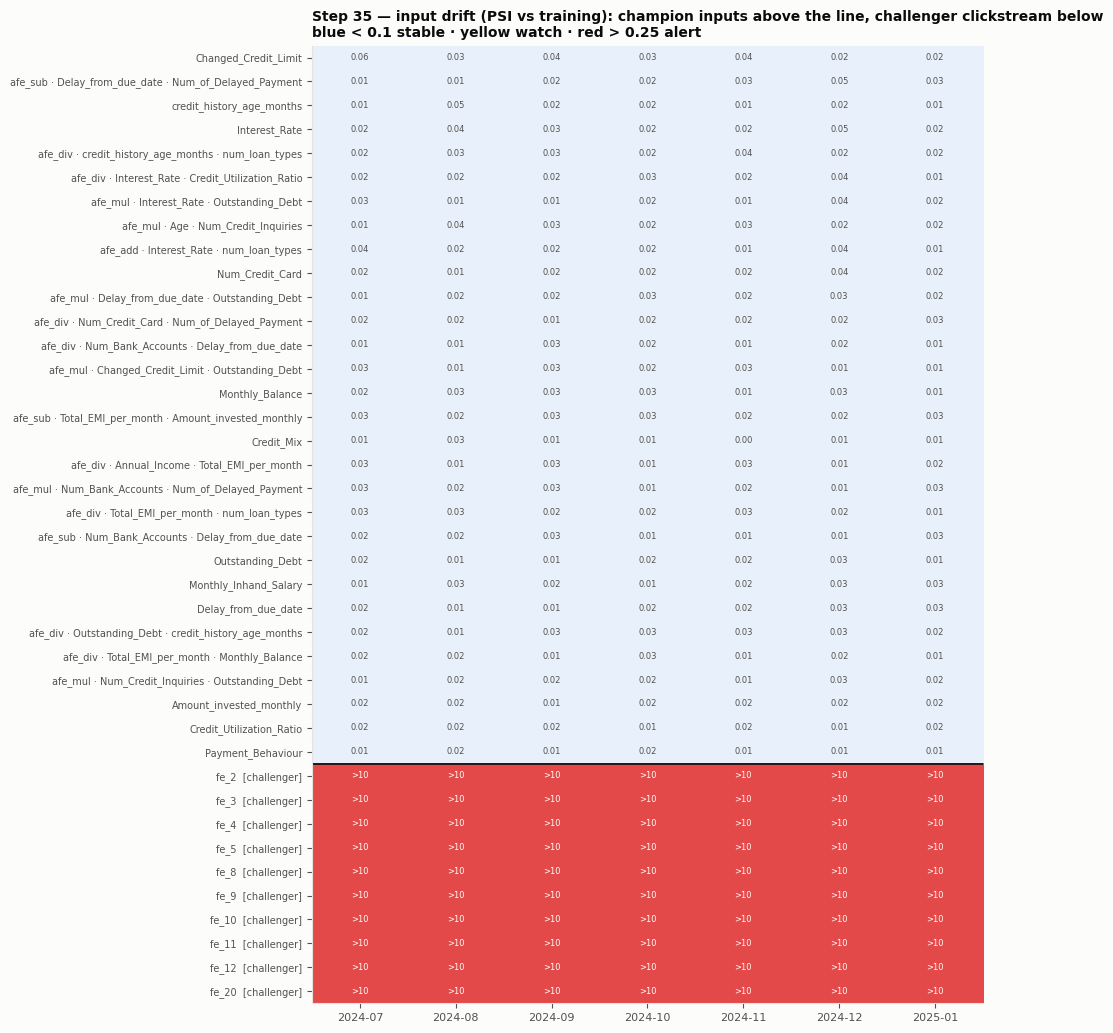

In [15]:
# Chart 1: input drift heatmap — PSI of every champion input by month (+ the challenger's clickstream inputs)
from matplotlib.colors import ListedColormap, BoundaryNorm
champ_psi = mon_features[mon_features["model"] == "champion"].pivot(index="feature", columns="month", values="psi")
click_psi = mon_features[(mon_features["model"] == "challenger") & mon_features["feature"].str.startswith("fe_")] \
    .pivot(index="feature", columns="month", values="psi")
champ_psi = champ_psi.loc[champ_psi.max(axis=1).sort_values(ascending=False).index]
heat = pd.concat([champ_psi, click_psi.loc[sorted(click_psi.index, key=lambda c: int(c.split("_")[1]))]])
labels_y = [f.replace("__", " · ") + ("  [challenger]" if f.startswith("fe_") else "") for f in heat.index]
cmap = ListedColormap(["#e8f1fb", "#f6d68a", "#e34948"])
norm = BoundaryNorm([0, MON_CFG["psi_watch"], MON_CFG["psi_alert"], 1e9], cmap.N)
fig, ax = plt.subplots(figsize=(10, 0.22 * len(heat) + 1.6))
ax.imshow(heat.values, aspect="auto", cmap=cmap, norm=norm)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(len(heat)), labels_y, fontsize=7)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.2f}" if v < 10 else ">10", ha="center", va="center", fontsize=6,
                color="white" if v > MON_CFG["psi_alert"] else INK_2)
ax.axhline(len(champ_psi) - 0.5, color=INK, linewidth=1.2)
ax.grid(False)
ax.set_title(f"Step 35 — input drift (PSI vs training): champion inputs above the line, challenger clickstream below\n"
             f"blue < {MON_CFG['psi_watch']} stable · yellow watch · red > {MON_CFG['psi_alert']} alert", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "35_1_input_drift_heatmap.png"), dpi=130, bbox_inches="tight")
plt.show()

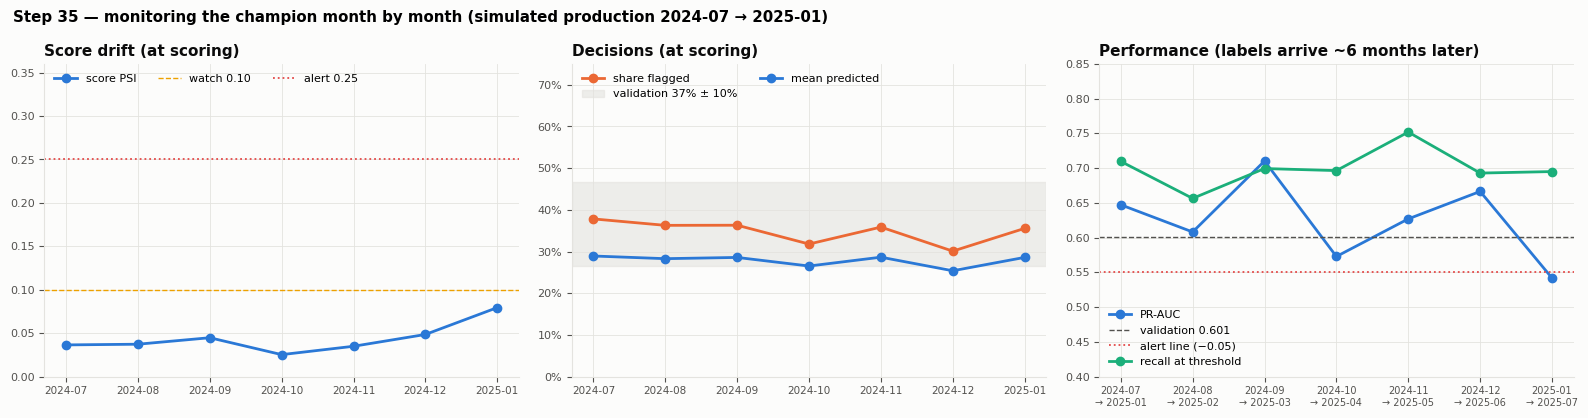

In [16]:
# Chart 2: score drift and decisions (available at scoring) | Chart 3: performance (available 6 months later)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(mon_month)); xl = mon_month["month"]
axes[0].plot(x, mon_month["score_psi"], "o-", color=SERIES[0], label="score PSI")
axes[0].axhline(MON_CFG["psi_watch"], color=SERIES[3], linestyle="--", linewidth=1, label="watch 0.10")
axes[0].axhline(MON_CFG["psi_alert"], color="#e34948", linestyle=":", linewidth=1.3, label="alert 0.25")
axes[0].set_ylim(0, 0.36); axes[0].set_title("Score drift (at scoring)"); axes[0].legend(loc="upper left", ncol=3)
axes[1].plot(x, mon_month["flagged_share"], "o-", color=SERIES[1], label="share flagged")
band = MON_CFG["flagged_share_alert_pp"] / 100
axes[1].axhspan(VAL_REF["flagged_share"] - band, VAL_REF["flagged_share"] + band, color=GRID, alpha=0.6,
                label=f"validation {VAL_REF['flagged_share']:.0%} ± {band:.0%}")
axes[1].plot(x, mon_month["mean_predicted"], "o-", color=SERIES[0], label="mean predicted")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_ylim(0, 0.75); axes[1].set_title("Decisions (at scoring)"); axes[1].legend(loc="upper left", ncol=2)
axes[2].plot(x, mon_month["pr_auc"], "o-", color=SERIES[0], label="PR-AUC")
axes[2].axhline(VAL_REF["pr_auc"], color=INK_2, linestyle="--", linewidth=1, label=f"validation {VAL_REF['pr_auc']:.3f}")
axes[2].axhline(VAL_REF["pr_auc"] - MON_CFG["pr_auc_drop_alert"], color="#e34948", linestyle=":", linewidth=1.3,
                label="alert line (−0.05)")
axes[2].plot(x, mon_month["recall"], "o-", color=SERIES[2], label="recall at threshold")
axes[2].set_ylim(0.4, 0.85); axes[2].set_title("Performance (labels arrive ~6 months later)")
axes[2].legend(loc="lower left")
for ax in axes:
    ax.set_xticks(x, xl, fontsize=7.5)
axes[2].set_xticks(x, [f"{m}\n→ {d[:7]}" for m, d in zip(xl, mon_month["labels_available_on"])], fontsize=7)
fig.suptitle("Step 35 — monitoring the champion month by month (simulated production 2024-07 → 2025-01)", x=0.01,
             ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "35_2_score_and_performance.png"), dpi=130, bbox_inches="tight")
plt.show()

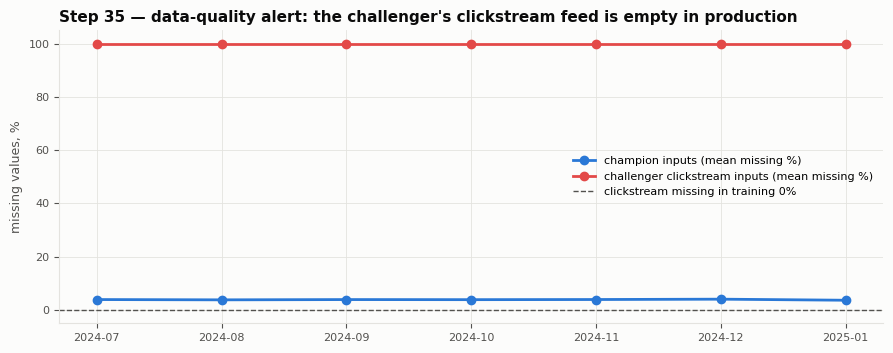

In [17]:
# Chart 4: what monitoring catches for the challenger — clickstream inputs missing in production
cl = mon_features[(mon_features["model"] == "challenger") & mon_features["feature"].str.startswith("fe_")]
miss = cl.groupby("month")["missing_pct"].mean()
ref_miss = cl.groupby("month")["ref_missing_pct"].mean().iloc[0]
champ_miss = mon_features[mon_features["model"] == "champion"].groupby("month")["missing_pct"].mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
xm = np.arange(len(miss))
ax.plot(xm, champ_miss.values, "o-", color=SERIES[0], label="champion inputs (mean missing %)")
ax.plot(xm, miss.values, "o-", color="#e34948", label="challenger clickstream inputs (mean missing %)")
ax.axhline(ref_miss, color=INK_2, linestyle="--", linewidth=1, label=f"clickstream missing in training {ref_miss:.0f}%")
ax.set_xticks(xm, miss.index); ax.set_ylim(-5, 105); ax.set_ylabel("missing values, %")
ax.legend(loc="center right", fontsize=8)
ax.set_title("Step 35 — data-quality alert: the challenger's clickstream feed is empty in production", loc="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "35_3_challenger_clickstream_missing.png"), dpi=130, bbox_inches="tight")
plt.show()

### Step 35 summary

- **Monitoring is replayed on 2024-07 → 2025-01** (the months after training), using the step-34 batches; outcome-based checks are dated when the month-6 labels would arrive.
- **Frozen reference and rules:** `monitoring_reference.json` (training bins and shares, validation metrics) and `monitoring_config.yaml` (PSI 0.10 / 0.25, missing +10 pp, flagged share ± 10 pp, PR-AUC −0.05, calibration ± 5 pp, recall −10 pp).
- **Outputs:** `monitoring_report.csv` (per month), `monitoring_feature_drift.csv` (per input and month), `alert_log.csv` and `alert_summary.csv`; charts 35_1–35_3.
- Results and alerts are summarised in the table above; the challenger's clickstream inputs show how monitoring would catch a broken feed automatically.

---

## Step 36 — Model governance, refresh SOP, rollback and deployment options

This step turns the monitoring results into **decisions with rules written down in advance**: who may change the production model, when it must be refreshed, how a new version is promoted, and how to go back.

### Governance (decisions)

| Topic | Decision |
|---|---|
| Model risk tier | **High** — the score influences credit decisions for customers; full documentation, independent validation, sign-off at every gate |
| Roles | **Model owner** (builds, monitors, proposes changes) · **Independent validator** (re-runs the tests, challenges results) · **Approver** (risk / credit committee; signs promotions) · **Platform** (runs the pipeline, executes alias moves) |
| Evidence per version | data contract version, split manifest, model card, metric contract, sign-off + approval, step-31 evaluation, step-32 robustness, registry version + checksum, lineage tags |
| Change log | every alias move and every policy decision appended to `governance_log.csv` (who, what, why, when) |
| Retention | every registry version and its predictions kept **≥ 7 years** (credit records); the previous champion kept deployable for rollback |
| Fairness | protected / sensitive attributes (age) are not model inputs; segment calibration (step 32) re-checked at every promotion |

### Refresh SOP (when and how)

| | Trigger | Action |
|---|---|---|
| **Scheduled** | every **6 months** (label maturity = 6 months) | **refit**: same features and settings on the most recent mature labels (rolling 18-month window) |
| **Triggered — refit** | input PSI > 0.25 on any champion input, or score PSI > 0.25, **2 consecutive months**; PR-AUC below the alert line **2 consecutive labelled months**; calibration gap > 5 pp **2 consecutive months** | refit early, same SOP |
| **Triggered — rebuild** | a source or schema change, a broken feed, a new product / policy, a regulatory request | re-run feature engineering and model development (steps 21–30) |
| **Watch only** | a single-month alert, PSI 0.10–0.25 | investigate (data issue? small sample?), record the finding, no model change |

**Promotion gates for any new version:** (1) pipeline tests and stress tests pass; (2) on the newest held-out month(s) the candidate's PR-AUC is **not lower than the champion's by more than 0.01** and its calibration gap is within ± 5 pp; (3) segment checks (step 32) show no new weakness; (4) **shadow scoring** — the candidate scores live batches in parallel for ≥ 1 month without driving decisions, flag rates compared; (5) model card + sign-off by the approver; then the `@champion` alias is moved.

**Rollback:** if a newly promoted version fails a post-deployment check (inference checks, flag rate outside the band, errors), the platform moves `@champion` back to the previous version immediately — no code change, no redeploy — and logs it. Below, this is **rehearsed on the real registry** (a drill) and the champion is restored.

In [18]:
# 1. Governance policy (machine-readable; read by the trigger evaluation below)
GOV = {
    "model": REGISTERED_MODEL, "risk_tier": "high (credit decisioning)",
    "roles": {"model_owner": "albertsoh", "independent_validator": "to be assigned (e.g. course reviewer)",
              "approver": "risk / credit committee", "platform": "ML platform team"},
    "scheduled_refit_months": 6, "training_window_months": 18,
    "triggers": {
        "input_drift": {"metric": "PSI (champion inputs)", "threshold": MON_CFG["psi_alert"], "consecutive_months": 2, "action": "refit"},
        "score_drift": {"metric": "score PSI", "threshold": MON_CFG["psi_alert"], "consecutive_months": 2, "action": "refit"},
        "performance": {"metric": "PR-AUC below validation - 0.05", "consecutive_months": 2, "action": "refit"},
        "calibration": {"metric": "|mean predicted - actual| > 5 pp", "consecutive_months": 2, "action": "refit"},
        "data_source": {"metric": "missing values +10 pp / schema change on a model input", "consecutive_months": 1, "action": "rebuild"},
    },
    "single_month_alert": "watch: investigate and record, no model change",
    "promotion_gates": ["pipeline + stress tests pass", "PR-AUC not lower than champion by > 0.01 on newest held-out months",
                        "calibration gap within +-5 pp", "no new segment weakness (step 32 checks)",
                        "shadow scoring >= 1 month", "model card + approver sign-off"],
    "rollback": "move @champion to the previous version; log; investigate",
    "retention_years": 7,
}
with open(os.path.join(DEP_DIR, "governance_policy.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(GOV, f, sort_keys=False, allow_unicode=True)

GOV_LOG = os.path.join(DEP_DIR, "governance_log.csv")
def log_event(event, detail, actor="platform (pipeline)"):
    row = pd.DataFrame([dict(ts=datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"), actor=actor, event=event,
                             detail=detail)])
    row.to_csv(GOV_LOG, mode="a", header=not os.path.exists(GOV_LOG), index=False)
print("Policy saved; triggers:", list(GOV["triggers"]))

Policy saved; triggers: ['input_drift', 'score_drift', 'performance', 'calibration', 'data_source']


In [19]:
# 2. Apply the refresh triggers to the step-35 monitoring results (champion and challenger)
def max_run(flags):
    best = cur = 0
    for f in flags:
        cur = cur + 1 if f else 0
        best = max(best, cur)
    return best

mm = mon_month.sort_values("month")
champ_drift = mon_features[mon_features["model"] == "champion"].groupby("month")["psi"].max().reindex(mm["month"])
click = mon_features[(mon_features["model"] == "challenger") & mon_features["feature"].str.startswith("fe_")]
click_missing_up = (click["missing_pct"] - click["ref_missing_pct"]).groupby(click["month"]).max().reindex(mm["month"])
rules = [
    ("champion", "input_drift", (champ_drift > GOV["triggers"]["input_drift"]["threshold"]).tolist(),
     f"max input PSI per month {champ_drift.min():.3f}–{champ_drift.max():.3f}"),
    ("champion", "score_drift", (mm["score_psi"] > GOV["triggers"]["score_drift"]["threshold"]).tolist(),
     f"score PSI {mm['score_psi'].min():.3f}–{mm['score_psi'].max():.3f}"),
    ("champion", "performance", (mm["pr_auc"] < VAL_REF["pr_auc"] - MON_CFG["pr_auc_drop_alert"]).tolist(),
     "PR-AUC below alert line in: " + (", ".join(mm.loc[mm["pr_auc"] < VAL_REF["pr_auc"] - MON_CFG["pr_auc_drop_alert"], "month"]) or "none")),
    ("champion", "calibration", (mm["calibration_gap_pp"].abs() > MON_CFG["calibration_gap_alert_pp"]).tolist(),
     f"calibration gap {mm['calibration_gap_pp'].min():+.1f} to {mm['calibration_gap_pp'].max():+.1f} pp"),
    ("challenger", "data_source", (click_missing_up > MON_CFG["missing_increase_alert_pp"]).tolist(),
     f"clickstream missing +{click_missing_up.max():.0f} pp vs training"),
]
dec_rows = []
for model, rule, flags, evidence in rules:
    need = GOV["triggers"][rule]["consecutive_months"]
    run_len, any_flag = max_run(flags), any(flags)
    status = "TRIGGERED" if run_len >= need else "WATCH (single month)" if any_flag else "not triggered"
    action = GOV["triggers"][rule]["action"] if status == "TRIGGERED" else ("investigate, no model change" if any_flag else "none")
    dec_rows.append(dict(model=model, trigger=rule, rule=f"{GOV['triggers'][rule]['metric']} for {need}+ consecutive month(s)",
                         months_flagged=int(sum(flags)), longest_run=run_len, status=status, action=action, evidence=evidence))
trigger_decisions = pd.DataFrame(dec_rows)
trigger_decisions.to_csv(os.path.join(DEP_DIR, "refresh_trigger_decisions.csv"), index=False)

champ_triggered = trigger_decisions.query("model == 'champion' and status == 'TRIGGERED'")
last_label = mm["labels_available_on"].max()
next_refit = (pd.Timestamp(last_label) + pd.DateOffset(months=0)).strftime("%Y-%m-%d")
REFRESH_DECISION = {
    "champion": ("REFIT now (triggered)" if len(champ_triggered) else
                 f"no early refit — keep @champion v{champ['version']}; investigate the single-month PR-AUC alert; "
                 f"scheduled refit when the newest labels are complete ({next_refit})"),
    "challenger": "not deployable while the clickstream feed is missing (rebuild trigger) — stays challenger, re-assess if the feed returns",
}
log_event("refresh review", f"champion: {REFRESH_DECISION['champion']} | challenger: {REFRESH_DECISION['challenger']}")
display(trigger_decisions.style.hide(axis="index"))
for k, v in REFRESH_DECISION.items():
    print(f"{k}: {v}")

model,trigger,rule,months_flagged,longest_run,status,action,evidence
champion,input_drift,PSI (champion inputs) for 2+ consecutive month(s),0,0,not triggered,none,max input PSI per month 0.033–0.060
champion,score_drift,score PSI for 2+ consecutive month(s),0,0,not triggered,none,score PSI 0.025–0.079
champion,performance,PR-AUC below validation - 0.05 for 2+ consecutive month(s),1,1,WATCH (single month),"investigate, no model change",PR-AUC below alert line in: 2025-01
champion,calibration,|mean predicted - actual| > 5 pp for 2+ consecutive month(s),0,0,not triggered,none,calibration gap -4.5 to +2.0 pp
challenger,data_source,missing values +10 pp / schema change on a model input for 1+ consecutive month(s),7,7,TRIGGERED,rebuild,clickstream missing +100 pp vs training


champion: no early refit — keep @champion v1; investigate the single-month PR-AUC alert; scheduled refit when the newest labels are complete (2025-07-01)
challenger: not deployable while the clickstream feed is missing (rebuild trigger) — stays challenger, re-assess if the feed returns


In [20]:
# 3. Rollback drill on the real registry: promote another version, check inference follows the alias, roll back
drill_rows = []
sample_month = inference_log["month"].iloc[-1] + "-01"
rows_s, _ = load_scoring_rows(sample_month)
def scores_now():
    m = resolve_alias("champion")
    return m["version"], np.asarray(m["pyfunc"].predict(rows_s[m["features"]]))[:, 1]

v0, p0 = scores_now()
baseline_v = int(client.get_model_version_by_alias(REGISTERED_MODEL, "baseline").version)
try:
    client.set_registered_model_alias(REGISTERED_MODEL, "champion", baseline_v)          # simulated bad promotion
    log_event("DRILL promote", f"@champion v{v0} -> v{baseline_v} (rollback drill)")
    v1, p1 = scores_now()
    drill_rows.append(dict(stage="after simulated promotion", champion_version=v1,
                           scores_changed=bool(not np.allclose(p0, p1)), note="inference follows the alias, no code change"))
finally:
    client.set_registered_model_alias(REGISTERED_MODEL, "champion", v0)                  # rollback = move alias back
    log_event("DRILL rollback", f"@champion restored to v{v0}")
v2, p2 = scores_now()
drill_rows.append(dict(stage="after rollback", champion_version=v2, scores_changed=bool(not np.allclose(p0, p2)),
                       note="identical to before the drill" if np.allclose(p0, p2) else "MISMATCH"))
rollback_drill = pd.DataFrame(drill_rows)
rollback_drill.to_csv(os.path.join(DEP_DIR, "rollback_drill.csv"), index=False)
assert v2 == v0 and np.array_equal(p0, p2), "rollback drill failed to restore the champion"
assert rollback_drill.iloc[0]["champion_version"] == baseline_v and rollback_drill.iloc[0]["scores_changed"]
print(f"Rollback drill passed on {len(rows_s)} loans from {sample_month[:7]}: alias move took effect immediately and "
      f"rollback restored v{v0} exactly")
rollback_drill.style.hide(axis="index")

Rollback drill passed on 526 loans from 2025-01: alias move took effect immediately and rollback restored v1 exactly


stage,champion_version,scores_changed,note
after simulated promotion,3,True,"inference follows the alias, no code change"
after rollback,1,False,identical to before the drill


### Deployment options

| Option | How | Fits when | Assessment for this model |
|---|---|---|---|
| **Batch scoring** (current) | scheduled job (cron / Airflow / Databricks Jobs) runs step 34 for new loans; reads Gold, loads `@champion`, writes predictions | decision can wait minutes to a day; features come from monthly snapshots | **Recommended.** Matches how features are built (snapshots as of loan start); simple, cheap, reproducible, fully audited. Move from monthly to **daily** batches so each new loan is scored the day it starts |
| **Real-time API** | `mlflow models serve -m models:/loan_default_30dpd_6mob@champion` or a FastAPI service in the same Docker image; called by the loan-origination system | an instant decision is needed at application | Option for later: requires the same features to be available online at application time (a feature-serving layer) and latency / uptime guarantees |
| **Streaming** | score events as they arrive (Kafka / Spark Structured Streaming) | continuous event data, decisions per event | Not needed: one decision per loan, inputs change monthly |
| **Embedded / in-database** | export the model (e.g. ONNX) into the core system or warehouse | the scoring must live inside another platform | Not needed; adds conversion and validation work for every version |

**Packaging:** the same Docker image runs the whole pipeline (tested clean from raw data); the model itself is pulled from the registry by alias, so a promotion or rollback never needs a new image.

In [21]:
# 4. Governance record for the step: what was decided, with evidence
gov_record = {
    "step": 36, "decided_ts": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "policy": "datamart/ml/deployment/v1/governance_policy.yaml",
    "refresh_decision": REFRESH_DECISION,
    "triggers": trigger_decisions[["model", "trigger", "status", "action"]].to_dict(orient="records"),
    "rollback_drill": "passed (alias move takes effect immediately; rollback restores the champion exactly)",
    "deployment": {"chosen": "batch scoring from the registry alias, daily schedule recommended",
                   "later_option": "real-time API (mlflow models serve / FastAPI) once features are available online",
                   "not_needed": ["streaming", "embedded / in-database"]},
    "champion": {"alias": "@champion", "version": int(champ["version"]), "threshold": float(champ["threshold"])},
    "approval_required_for": ["any alias move to a new version", "policy changes"],
}
with open(os.path.join(DEP_DIR, "governance_decision.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(gov_record, f, sort_keys=False, allow_unicode=True)
pd.read_csv(GOV_LOG).tail(6).style.hide(axis="index").set_caption("governance_log.csv (latest entries)")

ts,actor,event,detail
2026-10-21T01:01:02Z,platform (pipeline),refresh review,"champion: no early refit — keep @champion v1; investigate the single-month PR-AUC alert; scheduled refit when the newest labels are complete (2025-07-01) | challenger: not deployable while the clickstream feed is missing (rebuild trigger) — stays challenger, re-assess if the feed returns"
2026-10-21T01:01:02Z,platform (pipeline),DRILL promote,@champion v1 -> v3 (rollback drill)
2026-10-21T01:01:02Z,platform (pipeline),DRILL rollback,@champion restored to v1
2026-10-21T04:02:56Z,platform (pipeline),refresh review,"champion: no early refit — keep @champion v1; investigate the single-month PR-AUC alert; scheduled refit when the newest labels are complete (2025-07-01) | challenger: not deployable while the clickstream feed is missing (rebuild trigger) — stays challenger, re-assess if the feed returns"
2026-10-21T04:02:57Z,platform (pipeline),DRILL promote,@champion v1 -> v3 (rollback drill)
2026-10-21T04:02:57Z,platform (pipeline),DRILL rollback,@champion restored to v1


### Step 36 summary

- **Governance policy** (`governance_policy.yaml`): high-risk tier, named roles, evidence pack per version, change log, 7-year retention.
- **Refresh SOP:** scheduled refit every 6 months on the newest mature labels; early refit only when a trigger persists for **2 consecutive months**; rebuild on source / business change; single-month alerts are investigated, not acted on.
- **Applied to the monitoring results:** the champion's only alert (PR-AUC for 2025-01 loans) is a single month → **no early refit**, investigate, scheduled refit once the newest labels are complete. The challenger's clickstream feed is gone → rebuild trigger → **stays challenger**.
- **Promotion:** gates + shadow scoring + approver sign-off, then move `@champion`. **Rollback:** move the alias back — **rehearsed live** on the registry and restored exactly.
- **Deployment:** batch scoring from the registry alias (recommend daily); real-time API as a later option.